# STAT5A/STAT5B Phosphorylation and Dimerization: a Benchmark Model of Intracellular Signaling

From the benchmark collection _Benchmark problems for dynamic modeling of intracellular processes_:

__Helge Hass__, Center for Systems Biology (ZBSA), University of Freiburg, 79104 Freiburg, Germany; Center for Data Analysis and Modelling (FDM), University of Freiburg, 79104 Freiburg, Germany

__Carolin Loos__, Helmholtz Zentrum München-German Research Center for Environmental Health, Institute of Computational Biology, 85764 Neuherberg, Germany; Technische Universität München, Center for Mathematics, Chair of Mathematical Modeling of Biological Systems, 85748 Garching, Germany

__Elba Raimundez Alvarez__, Helmholtz Zentrum München-German Research Center for Environmental Health, Institute of Computational Biology, 85764 Neuherberg, Germany; Technische Universität München, Center for Mathematics, Chair of Mathematical Modeling of Biological Systems, 85748 Garching, Germany

__Jens Timmer__, Center for Systems Biology (ZBSA), University of Freiburg; Center for Data Analysis and Modelling (FDM), University of Freiburg; BIOSS Centre for Biological Signalling Studies, University of Freiburg, 79104 Freiburg, Germany

__Jan Hasenauer__, Helmholtz Zentrum München-German Research Center for Environmental Health, Institute of Computational Biology, 85764 Neuherberg, Germany; Technische Universität München, Center for Mathematics, Chair of Mathematical Modeling of Biological Systems, 85748 Garching, Germany

__Clemens Kreutz__, Center for Systems Biology (ZBSA), University of Freiburg; Center for Data Analysis and Modelling (FDM), University of Freiburg, 79104 Freiburg, Germany

Affiliations as in the bioRxiv preprint (10.1101/404590), the version read for this notebook.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import active_subspaces as ac
import STAT5_model as sm
from generate_data import read_csv

SEED = 2019
t_start = time.perf_counter()

### Summary

Hass et al. [[1]](https://doi.org/10.1093/bioinformatics/btz020) publish 20 ODE models of intracellular signaling, with data and parameter bounds, as benchmarks for parameter estimation; one of them, the model of Boehm et al. [[2]](https://doi.org/10.1021/pr5006923), describes how the hormone Epo drives phosphorylation, dimerization and nuclear shuttling of the transcription factors STAT5A and STAT5B. We rewrote the model's ODEs in scipy, sampled its 6 kinetic rate constants uniformly in $\log_{10}$ within one decade of the published best fit, and computed exact gradients of the time-averaged relative phosphorylation of STAT5A by forward sensitivity equations. The output has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 13.5$) that combines heterodimer import, Epo degradation and phosphorylation, with a sigmoidal sufficient summary plot, while two of the six rate constants have no visible effect in this box.

### Active subspaces in brief

For a scalar function $f(\mathbf x)$ of $m$ normalized inputs $\mathbf x \in [-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$. The eigenvalue $\lambda_i$ is the mean squared directional derivative of $f$ along $\mathbf w_i$, so a gap after the first $n$ eigenvalues means that $f$ changes mostly along the $n$ active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a sufficient summary plot) shows that structure. We estimate $\mathbf C$ by the Monte Carlo average of $\nabla f\,\nabla f^T$ over random samples and bootstrap the estimate. See Constantine [[3]](https://doi.org/10.1137/1.9781611973860).

### The model

Hass et al. [[1]](https://doi.org/10.1093/bioinformatics/btz020) collect 20 published ODE models of intracellular processes, with data, observation functions, noise models and parameter bounds, as benchmarks for parameter estimation. This notebook uses one of them, the model of Boehm et al. [[2]](https://doi.org/10.1021/pr5006923) (Table 1 of [[1]](https://doi.org/10.1093/bioinformatics/btz020): 8 species, 3 observables, 48 data points, 1 experimental condition, 9 estimated parameters). It describes how the hormone Epo makes the transcription factor isoforms STAT5A and STAT5B phosphorylate and form homo- and heterodimers, which move into the nucleus and back. The paper prints no equations; we rewrote them from the SBML file of the PEtab version of the problem [[4]](https://doi.org/10.1371/journal.pcbi.1008646) (Benchmark-Models-PEtab, `Boehm_JProteomeRes2014`). With $A, B$ the unphosphorylated STAT5A and STAT5B, $pAB, pAA, pBB$ the phosphorylated dimers in the cytoplasm, $nAB, nAA, nBB$ the dimers in the nucleus, compartment volumes $V_c = 1.4$, $V_n = 0.45$, and time in minutes,

$$
\begin{align}
\frac{dA}{dt} &= -2 w_{AA} - w_{AB} + \tfrac{V_n}{V_c}\left(2 k_{exp,hom}\, nAA + k_{exp,het}\, nAB\right), &
\frac{dpAA}{dt} &= w_{AA} - k_{imp,hom}\, pAA, &
\frac{dnAA}{dt} &= \tfrac{V_c}{V_n} k_{imp,hom}\, pAA - k_{exp,hom}\, nAA,\\
\frac{dB}{dt} &= -2 w_{BB} - w_{AB} + \tfrac{V_n}{V_c}\left(2 k_{exp,hom}\, nBB + k_{exp,het}\, nAB\right), &
\frac{dpBB}{dt} &= w_{BB} - k_{imp,hom}\, pBB, &
\frac{dnBB}{dt} &= \tfrac{V_c}{V_n} k_{imp,hom}\, pBB - k_{exp,hom}\, nBB,\\
& &
\frac{dpAB}{dt} &= w_{AB} - k_{imp,het}\, pAB, &
\frac{dnAB}{dt} &= \tfrac{V_c}{V_n} k_{imp,het}\, pAB - k_{exp,het}\, nAB,
\end{align}
$$

with $w_{AA} = k_{phos}\,\mathrm{Epo}(t)\,A^2$, $w_{AB} = k_{phos}\,\mathrm{Epo}(t)\,AB$, $w_{BB} = k_{phos}\,\mathrm{Epo}(t)\,B^2$, the decaying stimulus $\mathrm{Epo}(t) = 1.25\times 10^{-7} e^{-k_{deg} t}$, and $A(0) = 207.6\,r$, $B(0) = 207.6\,(1 - r)$, all dimers zero, with $r = 0.693$. The three observables, in per cent, are the measured relative quantities ($s = 0.107$, the fixed parameter `specC17`; $c = 1 - s$):

$$
\mathrm{pSTAT5A_{rel}} = \frac{100\,pAB + 200\,s\,pAA}{pAB + s A + 2 s\,pAA},\quad
\mathrm{pSTAT5B_{rel}} = \frac{100\,pAB + 200\,c\,pBB}{pAB + c B + 2 c\,pBB},\quad
\mathrm{rSTAT5A_{rel}} = \frac{100\,pAB + 100\,s A + 200\,s\,pAA}{2 pAB + s A + 2 s\,pAA + c B + 2 c\,pBB}.
$$

**Inputs.** The benchmark estimates 9 parameters: the 6 rate constants above and 3 noise standard deviations, one per observable. The noise parameters enter only the likelihood, not the model's predictions, so for the physical outputs used here the inputs are the $m = 6$ rate constants $\boldsymbol\theta$, as $\xi_j = \log_{10}\theta_j$ (the scale the benchmark uses for estimation, [[1]](https://doi.org/10.1093/bioinformatics/btz020) Sec. 4.2). `ratio` and `specC17` are fixed in the benchmark and held here.

**The study box (our choice).** The PEtab bounds are $[10^{-5}, 10^{5}]$ for every parameter, ten decades ([[1]](https://doi.org/10.1093/bioinformatics/btz020) Sec. 2.3: bounds "in most cases ... cover eight orders of magnitude or even more"). On that box the solves succeed (`DATA.md`), but the observables are mostly saturated at 0 or 100 % and say little about the dynamics that the data constrain. We sample $\boldsymbol\xi$ uniformly on the PEtab best fit $\pm 1$ decade, clipped to the PEtab bounds. Three best-fit values lie at or within a decade of a bound ($k_{exp,het}$ at $10^{-5}$, $k_{imp,hom}$ at $10^{4.99}$, $k_{phos}$ at $10^{4.20}$), so their intervals are shorter. The paper and the repository give no prior or study ranges; this box is ours, and the results depend on it.

**Quantities of interest.** The paper's objective is the likelihood of the 48 measurements. We use smooth physical outputs instead: the main QoI is the time average of $\mathrm{pSTAT5A_{rel}}$ over the experiment, $\frac{1}{240}\int_0^{240} \mathrm{pSTAT5A_{rel}}(t)\,dt$ (per cent). The data files also hold the time averages of the other two observables and all three observables at the 15 non-zero measurement times. Gradients with respect to $\boldsymbol\xi$ come from forward sensitivity equations solved with the model (`solve_ivp`, Radau, rtol = atol = $10^{-10}$); they agree with central differences to about $10^{-6}$ (`DATA.md`).

The table of inputs below is built from `STAT5_model.py`.

In [2]:
desc = {'Epo_degradation_BaF3': 'Epo degradation rate', 'k_exp_hetero': 'nuclear export, heterodimer',
        'k_exp_homo': 'nuclear export, homodimers', 'k_imp_hetero': 'nuclear import, heterodimer',
        'k_imp_homo': 'nuclear import, homodimers', 'k_phos': 'phosphorylation and dimerization'}
rows = ['| input $\\xi_j = \\log_{10}\\theta_j$ | description | units of $\\theta_j$ | best fit $\\theta_j$ | '
        'best fit $\\xi_j$ | lower | upper | PEtab bounds of $\\xi_j$ |', '|---|---|---|---|---|---|---|---|']
for j, n in enumerate(sm.NAMES):
    clip = []
    if sm.LOWER[j] == sm.PETAB_LOWER[j]: clip.append('lower clipped')
    if sm.UPPER[j] == sm.PETAB_UPPER[j]: clip.append('upper clipped')
    rows.append(f'| `{n}` | {desc[n]} | {sm.UNITS[j]} | {sm.NOMINAL_THETA[j]:.6g} | {sm.NOMINAL[j]:.4f} | '
                f'{sm.LOWER[j]:.4f} | {sm.UPPER[j]:.4f} | [{sm.PETAB_LOWER[j]:g}, {sm.PETAB_UPPER[j]:g}]'
                + (f' ({", ".join(clip)})' if clip else '') + ' |')
display(Markdown('\n'.join(rows)))
print(f'held: ratio = {sm.RATIO}, specC17 = {sm.SPECC17}, total STAT5 = {sm.STAT5_TOTAL}, Epo(0) = {sm.EPO0:g}, '
      f'V_cyt = {sm.V_CYT}, V_nuc = {sm.V_NUC}; t in [0, {sm.T_END:g}] min; Radau rtol = {sm.RTOL:g}, atol = {sm.ATOL:g}')

| input $\xi_j = \log_{10}\theta_j$ | description | units of $\theta_j$ | best fit $\theta_j$ | best fit $\xi_j$ | lower | upper | PEtab bounds of $\xi_j$ |
|---|---|---|---|---|---|---|---|
| `Epo_degradation_BaF3` | Epo degradation rate | 1/min | 0.0269825 | -1.5689 | -2.5689 | -0.5689 | [-5, 5] |
| `k_exp_hetero` | nuclear export, heterodimer | 1/min | 1.00068e-05 | -4.9997 | -5.0000 | -3.9997 | [-5, 5] (lower clipped) |
| `k_exp_homo` | nuclear export, homodimers | 1/min | 0.00617023 | -2.2097 | -3.2097 | -1.2097 | [-5, 5] |
| `k_imp_hetero` | nuclear import, heterodimer | 1/min | 0.0163679 | -1.7860 | -2.7860 | -0.7860 | [-5, 5] |
| `k_imp_homo` | nuclear import, homodimers | 1/min | 97749.4 | 4.9901 | 3.9901 | 5.0000 | [-5, 5] (upper clipped) |
| `k_phos` | phosphorylation and dimerization | 1/(conc^2 min) | 15766.5 | 4.1977 | 3.1977 | 5.0000 | [-5, 5] (upper clipped) |

held: ratio = 0.693, specC17 = 0.107, total STAT5 = 207.6, Epo(0) = 1.25e-07, V_cyt = 1.4, V_nuc = 0.45; t in [0, 240] min; Radau rtol = 1e-10, atol = 1e-10


#### The best-fit trajectory and the spread over the box

We plot the three observables at the PEtab best fit (the benchmark's estimated parameters; dots at the measurement times) and at 20 random points of the box. At the best fit the model reproduces the repository's reference simulation (`simulations.tsv`) to 2.0e-6 per cent (`DATA.md`). The measurements themselves are not shipped with this data set (`DATA.md`, License).

best fit: time averages over [0, 240] min: pSTAT5A_rel 60.75 %, pSTAT5B_rel 40.78 %, rSTAT5A_rel 38.17 %
best fit: pSTAT5A_rel peaks at 92.5 % at t = 21 min, 17.1 % at 240 min


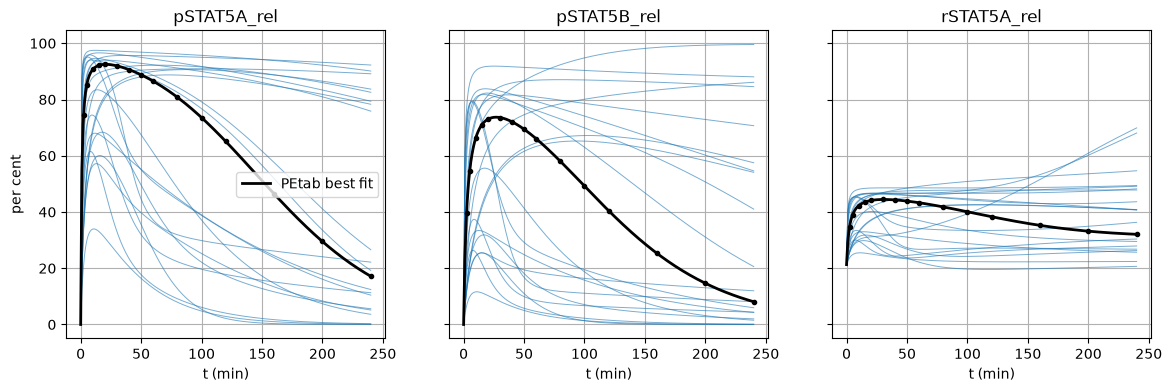

In [3]:
space = ac.Uniform(sm.LOWER, sm.UPPER, names=[f'log10_{n}' for n in sm.NAMES])
tt = np.linspace(0, sm.T_END, 241)
_, Onom = sm.trajectory(sm.NOMINAL, tt)
P20 = space.sample(20, rng=SEED)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for q in P20:
    _, O = sm.trajectory(q, tt)
    for i in range(3):
        axes[i].plot(tt, O[i], color='C0', lw=0.7, alpha=0.6)
for i in range(3):
    axes[i].plot(tt, Onom[i], 'k', lw=2, label='PEtab best fit')
    axes[i].plot(sm.TIMES, np.interp(sm.TIMES, tt, Onom[i]), 'ko', ms=3)
    axes[i].set_title(sm.OBS[i]); axes[i].set_xlabel('t (min)'); axes[i].grid(True)
axes[0].set_ylabel('per cent'); axes[0].legend()
plt.close(fig)
mean_nom = sm.qoi(sm.NOMINAL)[:3]
print('best fit: time averages over [0, 240] min:', ', '.join(f'{o} {v:.2f} %' for o, v in zip(sm.OBS, mean_nom)))
k = np.argmax(Onom[0])
print(f'best fit: pSTAT5A_rel peaks at {Onom[0, k]:.1f} % at t = {tt[k]:.0f} min, {Onom[0, -1]:.1f} % at 240 min')
fig

At the best fit, $\mathrm{pSTAT5A_{rel}}$ rises to 92.5 % at about 21 min and decays to 17.1 % at 240 min as the Epo stimulus is degraded; its time average is 60.75 %. Over the box the curves range from barely activated (peaks near 35 %) to nearly saturated for the whole experiment, so the time average spans most of [0, 100] %.

### Load the data

`generate_data.py` drew 1000 samples of $\boldsymbol\xi = \log_{10}\boldsymbol\theta$ from the box with `numpy.random.default_rng(2019)` and solved the model with its sensitivities for each one (16 minutes on two shared processes; `DATA.md`). The inputs are stored as $\log_{10}$ values, and the gradients are with respect to them; column `6*i + j` of `gradients.csv` is the derivative of output `i` with respect to $\xi_j$.

In [4]:
X = read_csv('inputs.csv')                                   # (1000, 6) log10(theta)
F = read_csv('outputs.csv')                                  # (1000, 48) time averages, observables at 15 times
G = read_csv('gradients.csv').reshape(len(X), F.shape[1], X.shape[1])   # d/d log10(theta)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}; outputs: '
      f'{", ".join(sm.QOI_NAMES[:4])}, ..., {sm.QOI_NAMES[-1]}')

inputs (1000, 6), outputs (1000, 48), gradients (1000, 48, 6); outputs: pSTAT5A_rel_mean, pSTAT5B_rel_mean, rSTAT5A_rel_mean, pSTAT5A_rel_t2.5, ..., rSTAT5A_rel_t240


We re-solve three samples with `STAT5_model.py` and compare with the stored outputs and gradients, and print the range of the three time averages over the 1000 samples.

In [5]:
for r in [0, 1, 2]:
    f_r, g_r = sm.qoi_and_grad(X[r])
    print(f'sample {r}: max absolute difference, outputs {np.max(np.abs(f_r - F[r])):.1e} %, '
          f'gradients {np.max(np.abs(g_r - G[r])):.1e} %; largest |gradient| {np.max(np.abs(G[r])):.1f} %')
for i in range(3):
    print(f'{sm.QOI_NAMES[i]}: {F[:, i].min():.2f} to {F[:, i].max():.2f} %, median {np.median(F[:, i]):.2f} %')

sample 0: max absolute difference, outputs 6.8e-10 %, gradients 2.1e-09 %; largest |gradient| 111.0 %


sample 1: max absolute difference, outputs 4.9e-12 %, gradients 4.3e-09 %; largest |gradient| 106.6 %


sample 2: max absolute difference, outputs 4.8e-12 %, gradients 5.0e-10 %; largest |gradient| 119.0 %
pSTAT5A_rel_mean: 1.55 to 98.52 %, median 57.17 %
pSTAT5B_rel_mean: 0.47 to 97.14 %, median 34.26 %
rSTAT5A_rel_mean: 19.66 to 70.49 %, median 36.99 %


The model reproduces the stored outputs to about $5\times 10^{-12}$ per cent and the gradients to at most $5\times 10^{-9}$ (gradients up to about 120 % per decade). Over the 1000 samples the time average of $\mathrm{pSTAT5A_{rel}}$ ranges from 1.55 to 98.52 % (median 57.17 %); $\mathrm{pSTAT5B_{rel}}$ spans a similar range, while $\mathrm{rSTAT5A_{rel}}$, a ratio of STAT5A to total STAT5, varies less (19.66 to 70.49 %).

### Estimate the active subspace of the time-averaged pSTAT5A

The model is cheap and smooth and its gradients agree with central differences to about $10^{-6}$ (`DATA.md`), so we use the gradient estimator (`estimator="as"`): $\hat{\mathbf C} = \frac1N\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, from $N = 1000$ samples. We pass the $\log_{10}$ inputs and the gradients with respect to them together with the uniform space on $\log_{10}\boldsymbol\theta$, and v1 normalizes both. The bootstrap uses 500 replicates. We orient $\mathbf w_1$ so that the output increases along it.

In [6]:
labels = [r'$k_{deg}$', r'$k_{exp,het}$', r'$k_{exp,hom}$', r'$k_{imp,het}$', r'$k_{imp,hom}$', r'$k_{phos}$']
names = list(sm.SHORT)
XX = space.to_normalized(X)
f = F[:, 0]
sub = ac.active_subspace(space=space, X=X, f=f, grads=G[:, 0], estimator='as',
                         nboot=500, bootstrap_vectors=2, rng=SEED, qoi='pSTAT5A_rel_mean')
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=2)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
print('eigenvalues:', np.array2string(lam, precision=4, max_line_width=120))
print(f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.1f}; '
      f'eigenvalue-gap rule: n = {sub.n}')
print(f'fraction of trace: lambda1 {lam[0] / lam.sum():.3f}, lambda1 + lambda2 {(lam[0] + lam[1]) / lam.sum():.3f}')

eigenvalues: [2.2120e+03 1.6405e+02 6.1001e+01 3.4874e+01 7.8133e-03 8.7213e-10]
lambda1/lambda2 = 13.5, lambda2/lambda3 = 2.7; eigenvalue-gap rule: n = 1
fraction of trace: lambda1 0.895, lambda1 + lambda2 0.961


### Results for the time-averaged pSTAT5A

#### Eigenvalues

95% bootstrap intervals: lambda1 [2.1e+03, 2.32e+03], lambda2 [147, 182], lambda3 [54.1, 68.2]


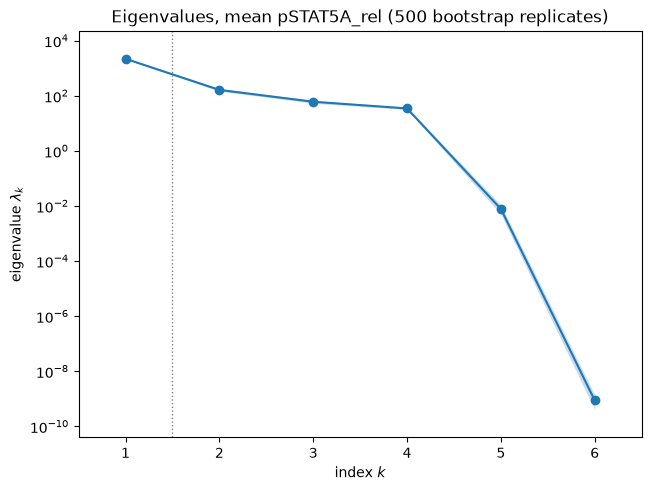

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
ax.set_title('Eigenvalues, mean pSTAT5A_rel (500 bootstrap replicates)')
lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, :3], [2.5, 97.5], axis=0)
print('95% bootstrap intervals: ' + ', '.join(f'lambda{i + 1} [{lo[i]:.3g}, {hi[i]:.3g}]' for i in range(3)))
fig

The first eigenvalue, $\lambda_1 = 2212$, is 13.5 times $\lambda_2 = 164$ and holds 0.895 of the trace; its 95 % bootstrap interval, [2100, 2320], is far from that of $\lambda_2$, [147, 182], and the eigenvalue-gap rule picks $n = 1$. The next ratio is smaller ($\lambda_2/\lambda_3 = 2.7$). The last two eigenvalues, $7.8\times 10^{-3}$ and $8.7\times 10^{-10}$, are essentially zero: two inputs do not affect the output (below).

#### Subspace errors

mean bootstrap subspace distance: n = 1: 0.012, n = 2: 0.042, n = 3: 0.062, n = 4: 0.001


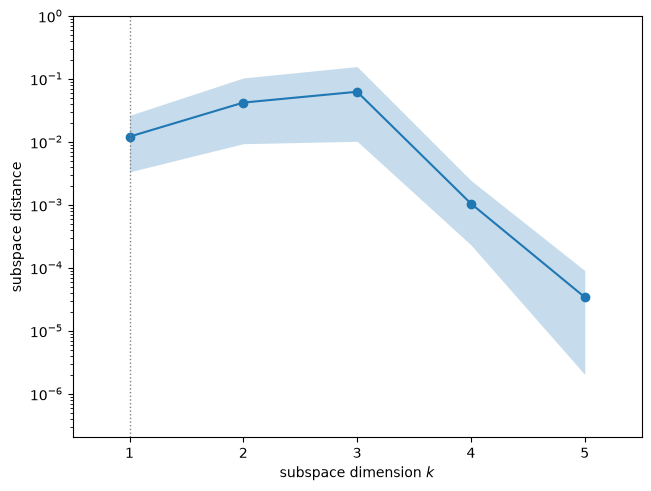

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
d = sub.bootstrap_distances.mean(axis=0)
print('mean bootstrap subspace distance: ' + ', '.join(f'n = {i + 1}: {d[i]:.3f}' for i in range(4)))
fig

The mean bootstrap distance of the one-dimensional subspace is 0.012, so $\mathbf w_1$ is well determined; it is 0.042 and 0.062 for $n = 2$ and 3. The four-dimensional subspace is almost exact (0.001), because it is the span of the four inputs that matter.

#### Eigenvectors

w1: k_imp,het -0.812, k_deg -0.478, k_phos +0.321, k_exp,hom -0.097, k_exp,het +0.001, k_imp,hom -0.000
w2: k_deg +0.677, k_imp,het -0.562, k_phos -0.454, k_exp,hom -0.137, k_exp,het +0.002, k_imp,hom -0.000
activity scores (scaled to max 1): k_imp,het 1.00e+00, k_deg 3.92e-01, k_phos 1.90e-01, k_exp,hom 5.34e-02, k_exp,het 6.53e-06, k_imp,hom 1.04e-12


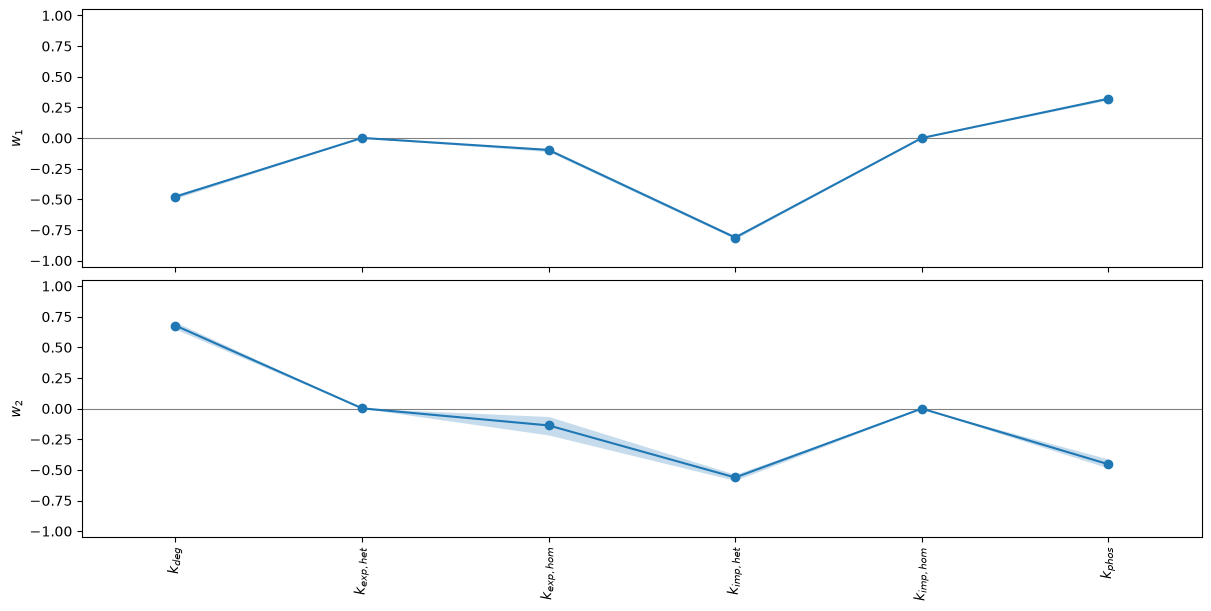

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile',
                                          figsize=(12, 6))
w1, w2 = sub.W[:, 0], sub.W[:, 1]
print('w1:', ', '.join(f'{names[j]} {w1[j]:+.3f}' for j in np.argsort(-np.abs(w1))))
print('w2:', ', '.join(f'{names[j]} {w2[j]:+.3f}' for j in np.argsort(-np.abs(w2))))
act = (sub.W**2 * lam) @ np.ones(len(lam))
act = act / act.max()
print('activity scores (scaled to max 1):', ', '.join(f'{names[j]} {act[j]:.2e}' for j in np.argsort(-act)))
fig

$\mathbf w_1$ is dominated by heterodimer import $k_{imp,het}$ (−0.812), Epo degradation $k_{deg}$ (−0.478) and phosphorylation $k_{phos}$ (+0.321), with a small weight on homodimer export $k_{exp,hom}$ (−0.097). Phosphorylated STAT5A stays high on average when phosphorylation is fast and the stimulus persists, and falls when the heterodimer moves quickly into the nucleus. $\mathbf w_2$ mixes the same three inputs with different signs. The activity scores (mean squared derivatives, scaled to max 1) rank $k_{imp,het}$ 1.00, $k_{deg}$ 0.392, $k_{phos}$ 0.190 and $k_{exp,hom}$ 0.0534; $k_{exp,het}$ ($6.5\times 10^{-6}$) and $k_{imp,hom}$ ($1.0\times 10^{-12}$) are negligible. Both lie where the benchmark's best fit is at or near a bound: with $k_{exp,het} \le 10^{-4}$/min almost no heterodimer is exported within 240 min, and with $k_{imp,hom} \ge 10^{4}$/min phosphorylated homodimers enter the nucleus as soon as they form, so the exact rate does not matter.

#### Sufficient summary plots

corr(w1^T x, f) = 0.9683


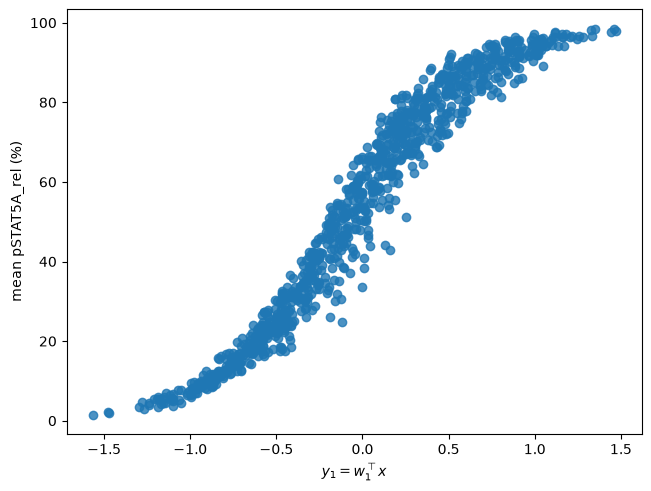

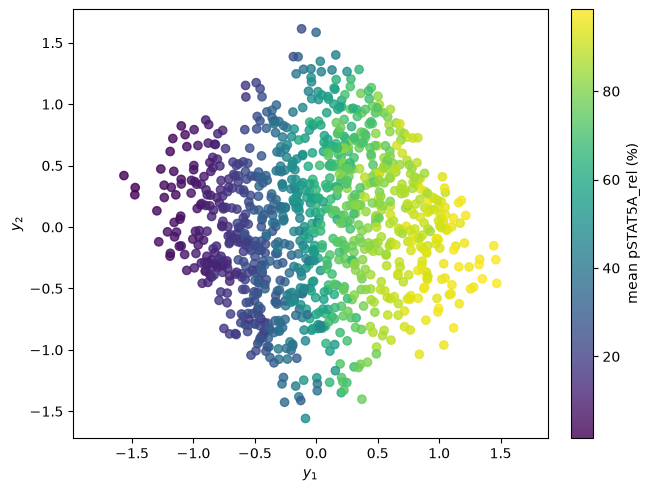

In [10]:
y = XX @ sub.W[:, :2]
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='mean pSTAT5A_rel (%)')
print(f'corr(w1^T x, f) = {np.corrcoef(y[:, 0], f)[0, 1]:.4f}')
display(fig); plt.close(fig)
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label='mean pSTAT5A_rel (%)')
fig

The one-dimensional summary plot is a sigmoid: the output rises from about 2 % to 98 % along $y_1 = \mathbf w_1^T\mathbf x$, with correlation 0.9683 between $y_1$ and the output. The scatter about the curve is largest in the middle of the range. In the two-dimensional plot the color changes mostly along $y_1$, with a weaker trend along $y_2$.

#### Surrogates on the active variables

We fit polynomials in one and two active variables and report the leave-one-out $R^2$.

1-D polynomial, degree 3: LOO R^2 = 0.9668
1-D polynomial, degree 5: LOO R^2 = 0.9697
2-D polynomial, degree 3: LOO R^2 = 0.9762
2-D polynomial, degree 5: LOO R^2 = 0.9812
2-D, degree 5: RMS residual 3.85 %, max |residual| 13.18 % (outputs 1.6 to 98.5 %)


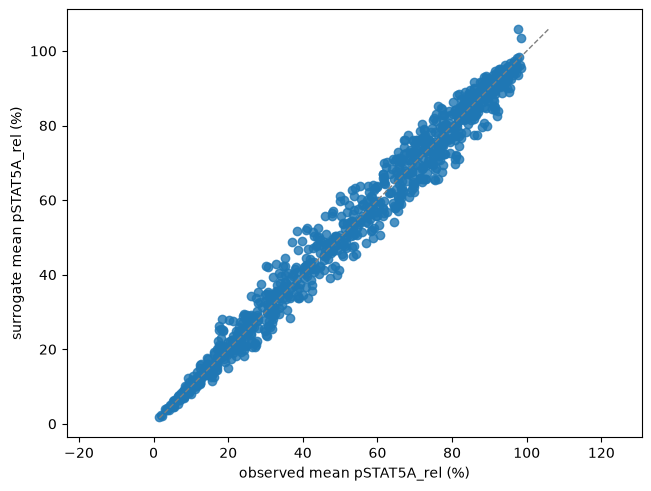

In [11]:
for n in [1, 2]:
    s_n = ac.with_dimension(sub, n)
    for deg in [3, 5]:
        srg = ac.fit_surrogate(X=X, f=f, space=space, subspace=s_n, kind='poly', degree=deg)
        print(f'{n}-D polynomial, degree {deg}: LOO R^2 = {srg.loo_r_squared:.4f}')
sub2 = ac.with_dimension(sub, 2)
srg = ac.fit_surrogate(X=X, f=f, space=space, subspace=sub2, kind='poly', degree=5)
res = f - srg.evaluate(XX @ sub2.W1)
print(f'2-D, degree 5: RMS residual {np.sqrt(np.mean(res**2)):.2f} %, max |residual| {np.abs(res).max():.2f} % '
      f'(outputs {f.min():.1f} to {f.max():.1f} %)')
fig, ax = ac.plotting.plot_surrogate_fit(srg, X=X, f=f, qoi_label='mean pSTAT5A_rel (%)')
fig

One active variable already gives a leave-one-out $R^2$ of 0.9668 (cubic) and 0.9697 (quintic). Two active variables raise it to 0.9762 (cubic) and 0.9812 (quintic); the quintic in two variables has an RMS residual of 3.85 % (maximum 13.18 %) on outputs from 1.6 to 98.5 %.

### The other outputs

The same estimator for the time averages of the other two observables, and for $\mathrm{pSTAT5A_{rel}}$ at each of the 15 measurement times (no bootstrap for the time series).

In [12]:
print('QoI                  lambda1/lambda2  lambda2/lambda3  n   w1 (largest 3)')
others = {}
for i in [1, 2]:
    s = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as', nboot=500, rng=SEED)
    s = ac.orient(s, by='covariance', X=X, f=F[:, i], columns=1)
    others[i] = s
    l = s.eigenvalues
    print(f'{sm.QOI_NAMES[i]:20s} {l[0] / l[1]:12.1f} {l[1] / l[2]:15.1f}    {s.n}   '
          + ', '.join(f'{names[j]} {s.W[j, 0]:+.2f}' for j in np.argsort(-np.abs(s.W[:, 0]))[:3]))
print('\npSTAT5A_rel(t):')
print('  t (min)  lambda1/lambda2  lambda2/lambda3  n  w1 (largest 3)')
rat_t = []
for k, t in enumerate(sm.TIMES):
    s = ac.active_subspace(space=space, grads=G[:, 3 + k], estimator='as')
    s = ac.orient(s, by='reference', reference=sub, columns=1)
    l = s.eigenvalues
    rat_t.append(l[0] / l[1])
    print(f'  {t:6.1f}  {l[0] / l[1]:12.1f} {l[1] / l[2]:15.1f}     {s.n}  '
          + ', '.join(f'{names[j]} {s.W[j, 0]:+.2f}' for j in np.argsort(-np.abs(s.W[:, 0]))[:3]))

QoI                  lambda1/lambda2  lambda2/lambda3  n   w1 (largest 3)


pSTAT5B_rel_mean             11.4             1.8    1   k_imp,het -0.71, k_deg -0.54, k_phos +0.44


rSTAT5A_rel_mean              3.3             3.6    1   k_exp,hom +0.59, k_deg -0.54, k_phos +0.47

pSTAT5A_rel(t):
  t (min)  lambda1/lambda2  lambda2/lambda3  n  w1 (largest 3)
     2.5         131.7             1.7     1  k_phos +1.00, k_deg -0.08, k_imp,het -0.06
     5.0          37.9             1.3     1  k_phos +0.98, k_deg -0.16, k_imp,het -0.12
    10.0          10.8             1.4     1  k_phos +0.90, k_deg -0.32, k_imp,het -0.29
    15.0           5.6             2.2     1  k_phos +0.75, k_imp,het -0.51, k_deg -0.42
    20.0           4.9             3.1     1  k_imp,het -0.69, k_phos +0.57, k_deg -0.43
    30.0           5.7             4.6     1  k_imp,het -0.83, k_deg -0.40, k_phos +0.38
    40.0           7.0             5.1     1  k_imp,het -0.86, k_deg -0.40, k_phos +0.31
    50.0           8.2             5.1     1  k_imp,het -0.86, k_deg -0.42, k_phos +0.29
    60.0           9.1             5.0     1  k_imp,het -0.85, k_deg -0.43, k_phos +0.28
    80.0          1

The time average of $\mathrm{pSTAT5B_{rel}}$ behaves like that of $\mathrm{pSTAT5A_{rel}}$ ($\lambda_1/\lambda_2 = 11.4$, the same three leading inputs). The time average of $\mathrm{rSTAT5A_{rel}}$ has a weaker gap ($\lambda_1/\lambda_2 = 3.3$, $\lambda_2/\lambda_3 = 3.6$), led by homodimer export $k_{exp,hom}$ (+0.59). Over time, $\mathrm{pSTAT5A_{rel}}$ is one-dimensional early on and controlled by phosphorylation alone ($\lambda_1/\lambda_2 = 131.7$ at 2.5 min, $\mathbf w_1 \approx$ $k_{phos}$). From 20 min on, heterodimer import leads (−0.69 at 20 min, −0.85 to −0.86 from 40 min), and $\lambda_1/\lambda_2$ is between 4.9 and 11.5. The time average combines both phases, which is why its $\mathbf w_1$ has all three weights.

### Comparison with the paper

The paper has no active subspace, sensitivity study or forward uncertainty propagation: it introduces the benchmark collection and uses it for multistart optimization studies. The table compares what can be compared; "not reported" marks quantities the paper does not give.

In [13]:
rows = ['| quantity | paper [1] | this notebook |', '|---|---|---|',
        '| species, observables, data points, conditions | 8, 3, 48, 1 (Table 1) | 8 states, 3 observables, '
        f'{3 * len(sm.TIMES)} observable outputs at the 15 non-zero measurement times + 3 time averages, 1 condition |',
        '| estimated parameters | 9 (Table 1) | 6 kinetic inputs (the 3 noise parameters affect only the likelihood) |',
        '| parameter bounds | "in most cases ... eight orders of magnitude or even more" (Sec. 2.3) | '
        'PEtab $[10^{-5}, 10^{5}]$ (10 decades); study box: best fit $\\pm$ 1 decade, clipped |',
        '| parameter scale | $\\log_{10}$ recommended (Sec. 4.2) | uniform in $\\log_{10}\\theta$ |',
        '| best-fit parameters | provided with the collection (not printed in the paper) | PEtab `nominalValue` |',
        f'| mean pSTAT5A_rel at the best fit | not reported | {mean_nom[0]:.2f} % |',
        f'| active subspace, mean pSTAT5A_rel: $\\lambda_1/\\lambda_2$, $\\lambda_2/\\lambda_3$ | not reported | '
        f'{lam[0] / lam[1]:.1f}, {lam[1] / lam[2]:.1f} |',
        '| leading inputs ($\\mathbf w_1$) | not reported | '
        + ', '.join(f'{names[j]} {w1[j]:+.2f}' for j in np.argsort(-np.abs(w1))[:3]) + ' |',
        f'| LOO $R^2$, 2-D quintic surrogate | not reported | {srg.loo_r_squared:.4f} |']
display(Markdown('\n'.join(rows)))
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

| quantity | paper [1] | this notebook |
|---|---|---|
| species, observables, data points, conditions | 8, 3, 48, 1 (Table 1) | 8 states, 3 observables, 45 observable outputs at the 15 non-zero measurement times + 3 time averages, 1 condition |
| estimated parameters | 9 (Table 1) | 6 kinetic inputs (the 3 noise parameters affect only the likelihood) |
| parameter bounds | "in most cases ... eight orders of magnitude or even more" (Sec. 2.3) | PEtab $[10^{-5}, 10^{5}]$ (10 decades); study box: best fit $\pm$ 1 decade, clipped |
| parameter scale | $\log_{10}$ recommended (Sec. 4.2) | uniform in $\log_{10}\theta$ |
| best-fit parameters | provided with the collection (not printed in the paper) | PEtab `nominalValue` |
| mean pSTAT5A_rel at the best fit | not reported | 60.75 % |
| active subspace, mean pSTAT5A_rel: $\lambda_1/\lambda_2$, $\lambda_2/\lambda_3$ | not reported | 13.5, 2.7 |
| leading inputs ($\mathbf w_1$) | not reported | k_imp,het -0.81, k_deg -0.48, k_phos +0.32 |
| LOO $R^2$, 2-D quintic surrogate | not reported | 0.9812 |

Total run time: 25 s


The model matches the paper's description of the Boehm problem (8 species, 3 observables, 48 data points, 1 condition). At the best fit it reproduces the repository's reference simulation to 2.0e-6 per cent, and the negative log-likelihood of the 48 measurements is 138.222 (scratch check in `DATA.md`). The number of inputs differs: the benchmark estimates 9 parameters, but 3 of them are noise standard deviations, which change the likelihood and not the observables, so a physical output has 6 inputs. The study box (best fit $\pm$ 1 decade) is our choice; the PEtab bounds span ten decades (the paper: "eight orders of magnitude or even more"), where about 80 % of random points give a time-averaged $\mathrm{pSTAT5A_{rel}}$ below 1 % (`DATA.md`). The active subspace found here describes the model near its fit to the data, not over the whole benchmark box.

### References

[[1]][R1] H. Hass, C. Loos, E. Raimúndez-Álvarez, J. Timmer, J. Hasenauer and C. Kreutz. _Benchmark problems for dynamic modeling of intracellular processes_. Bioinformatics, 35(17):3073–3082, 2019. doi:10.1093/bioinformatics/btz020

[[2]][R2] M. E. Boehm, L. Adlung, M. Schilling, S. Roth, U. Klingmüller and W. D. Lehmann. _Identification of isoform-specific dynamics in phosphorylation-dependent STAT5 dimerization by quantitative mass spectrometry and mathematical modeling_. Journal of Proteome Research, 13(12):5685–5694, 2014. doi:10.1021/pr5006923

[[3]][R3] P. G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, Philadelphia, 2015. doi:10.1137/1.9781611973860

[[4]][R4] L. Schmiester, Y. Schälte, F. T. Bergmann et al. _PEtab—Interoperable specification of parameter estimation problems in systems biology_. PLoS Computational Biology, 17(1):e1008646, 2021. doi:10.1371/journal.pcbi.1008646

[R1]: https://doi.org/10.1093/bioinformatics/btz020
[R2]: https://doi.org/10.1021/pr5006923
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.1371/journal.pcbi.1008646

### Acknowledgments

From [[1]][R1]: the work was supported by the German Ministry of Education and Research by the grant EA:Sys (FKZ 031L0080), the grant SYS-Stomach (01ZX1310B) and the grant INCOME (FKZ 01ZX1705A), and by the German Research Foundation (DFG) via grant TRR179; the authors also acknowledge support for high-performance computing by the state of Baden-Württemberg through the bwHPC initiative, which is supported by DFG grant INST 35/1134-1 FUGG.